<a href="https://colab.research.google.com/github/abubakarsadiq242/AI-Marketing-Conversion-Predictor/blob/main/Marketing_Conversion_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

import joblib
import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ML Project/digital_marketing_campaign_dataset.csv")
df.head()

,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
selected_features = [
    'Age',
    'Gender',
    'Income',
    'CampaignChannel',
    'AdSpend',
    'ConversionRate',
    'PreviousPurchases',
    'EmailClicks',
    'AdvertisingPlatform',
    'AdvertisingTool'
]

X = df[selected_features]
y = df['Conversion']
y = df['Conversion']

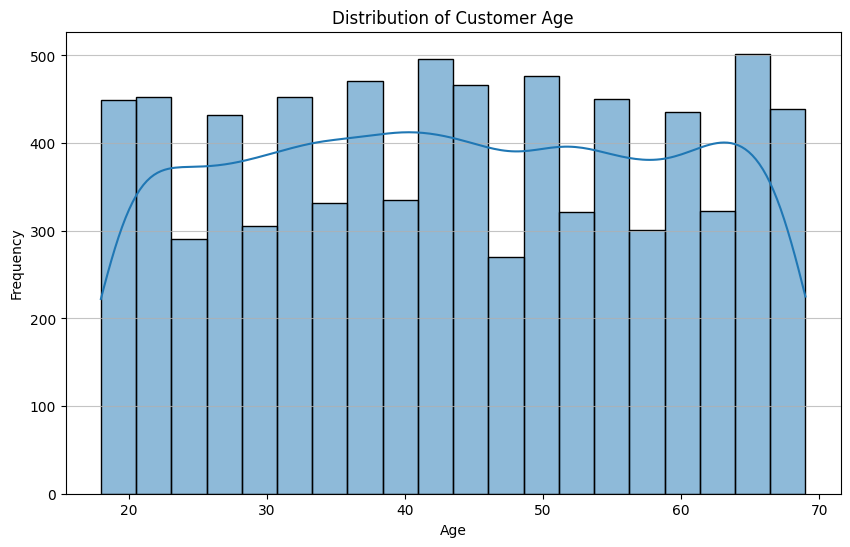

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the distribution of 'Age'
plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], kde=True, bins=20)
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

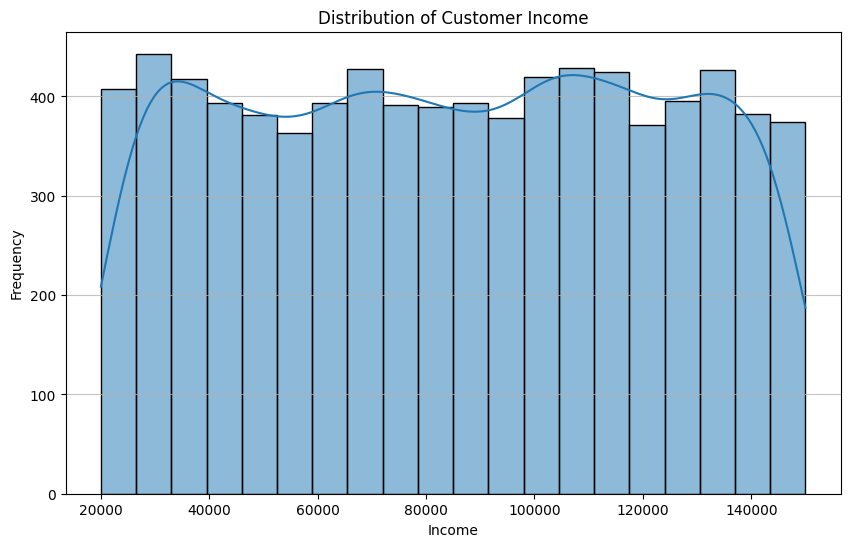

In [ ]:
# Plotting the distribution of 'Income'
plt.figure(figsize=(10, 6))
sns.histplot(df['Income'], kde=True, bins=20)
plt.title('Distribution of Customer Income')
plt.xlabel('Income')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

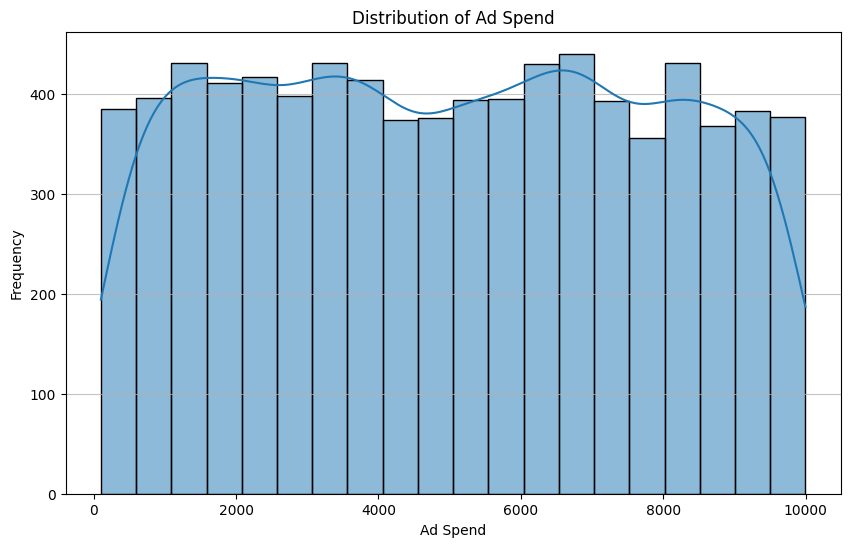

In [ ]:
# Plotting the distribution of 'AdSpend'
plt.figure(figsize=(10, 6))
sns.histplot(df['AdSpend'], kde=True, bins=20)
plt.title('Distribution of Ad Spend')
plt.xlabel('Ad Spend')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [ ]:
le = LabelEncoder()

for col in X.columns:
    if X[col].dtype == 'object':
        X[col] = le.fit_transform(X[col])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8775
              precision    recall  f1-score   support

           0       0.47      0.09      0.15       194
           1       0.89      0.99      0.93      1406

    accuracy                           0.88      1600
   macro avg       0.68      0.54      0.54      1600
weighted avg       0.84      0.88      0.84      1600



In [ ]:
joblib.dump(model, "model.pkl")
joblib.dump(list(X.columns), "columns.pkl")

['columns.pkl']

In [ ]:
# =========================================
# INSTALL & IMPORT
# =========================================
# !pip install ipywidgets

import ipywidgets as widgets
from IPython.display import display, HTML
import numpy as np
import joblib

# =========================================
# LOAD MODEL
# =========================================
model = joblib.load("model.pkl")

# =========================================
# HEADER
# =========================================
display(HTML("""
<h2 style='color:#2E86C1;'>AI Marketing Conversion Predictor</h2>
<p>Fill in key campaign details and click Predict.</p>
<hr>
"""))

# =========================================
# INPUT FIELDS (BASED ON YOUR REQUEST)
# =========================================

# Sliders (Ranges)
age = widgets.IntSlider(description='Age', min=18, max=70, value=25)

income = widgets.IntSlider(description='Income', min=1000, max=200000, step=1000, value=50000)

ad_spend = widgets.IntSlider(description='Ad Spend', min=0, max=10000, step=100, value=1000)

conversion_rate = widgets.FloatSlider(description='Conversion Rate', min=0, max=1, step=0.01, value=0.1)

previous_purchases = widgets.IntSlider(description='Previous Purchases', min=0, max=50, value=2)

email_clicks = widgets.IntSlider(description='Email Clicks', min=0, max=100, value=5)

# Dropdowns (Text fields)
gender = widgets.Dropdown(
    options=['Male', 'Female'],
    description='Gender'
)

campaign_channel = widgets.Dropdown(
    options=['Email', 'Social Media', 'SEO', 'Ads'],
    description='Campaign Channel'
)

advertising_platform = widgets.Dropdown(
    options=['Google', 'Facebook', 'Instagram', 'LinkedIn'],
    description='Platform'
)

advertising_tool = widgets.Dropdown(
    options=['Tool A', 'Tool B', 'Tool C'],
    description='Ad Tool'
)

# =========================================
# BUTTONS
# =========================================
predict_btn = widgets.Button(description="Predict", button_style='success')
reset_btn = widgets.Button(description="Reset", button_style='warning')

buttons = widgets.HBox([predict_btn, reset_btn])

# =========================================
# OUTPUT
# =========================================
output = widgets.Output()

# =========================================
# ENCODING (MATCH TRAINING)
# =========================================
def encode_inputs():
    gender_val = 1 if gender.value == 'Male' else 0

    channel_map = {'Email':0, 'Social Media':1, 'SEO':2, 'Ads':3}
    platform_map = {'Google':0, 'Facebook':1, 'Instagram':2, 'LinkedIn':3}
    tool_map = {'Tool A':0, 'Tool B':1, 'Tool C':2}

    return [
        age.value,
        gender_val,
        income.value,
        channel_map[campaign_channel.value],
        ad_spend.value,
        conversion_rate.value,
        previous_purchases.value,
        email_clicks.value,
        platform_map[advertising_platform.value],
        tool_map[advertising_tool.value]
    ]

# =========================================
# PREDICT FUNCTION
# =========================================
def predict(b):
    with output:
        output.clear_output()
        try:
            data = np.array(encode_inputs()).reshape(1, -1)
            result = model.predict(data)[0]

            if result == 1:
                display(HTML("<b style='color:green;'>Customer is likely to convert ✅</b>"))
            else:
                display(HTML("<b style='color:red;'>Customer is not likely to convert ❌</b>"))

        except Exception as e:
            print("Error:", e)

# =========================================
# RESET FUNCTION
# =========================================
def reset(b):
    age.value = 25
    income.value = 50000
    ad_spend.value = 1000
    conversion_rate.value = 0.1
    previous_purchases.value = 2
    email_clicks.value = 5
    gender.value = 'Male'
    campaign_channel.value = 'Email'
    advertising_platform.value = 'Google'
    advertising_tool.value = 'Tool A'

    with output:
        output.clear_output()

# =========================================
# LINK BUTTONS
# =========================================
predict_btn.on_click(predict)
reset_btn.on_click(reset)

# =========================================
# DISPLAY UI
# =========================================
display(HTML("<b>Enter Details:</b>"))

display(
    widgets.VBox([
        age, gender, income,
        campaign_channel, ad_spend,
        conversion_rate,
        previous_purchases,
        email_clicks,
        advertising_platform,
        advertising_tool
    ])
)

display(buttons)
display(output)

Output()